In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [28]:
import pandas as pd
import numpy as np
from ydata_profiling import ProfileReport
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [29]:
df = pd.read_csv("HotelBookings.csv")

In [5]:
profile = ProfileReport(df)
#profile.to_notebook_iframe()
#profile.to_file("hotelbookings_profiling_report.html")

In [6]:
## CREATING NEW VARIABLES
# create arrival_date to get the booking_date by arrival_date - lead_time
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-" + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)
df["booking_date"] = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")

# create arrival_dow
df["arrival_dow"] = df["arrival_date"].dt.dayofweek

# create has_children variable by adding children and babies tgt
df["has_children"] = ((df["children"].fillna(0) + df["babies"]) > 0).astype(int)

# create has_prior_cancel from previous_cancellations
df["has_prior_cancel"] = (df["previous_cancellations"] > 0).astype(int)

# create room_changed = (reserved != assigned) room type
df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)

# create prior_cancel_rate: what proportion of this guest’s past bookings they cancelled.
prior_total = df["previous_cancellations"] + df["previous_bookings_not_canceled"]

df["has_history"] = (prior_total > 0).astype(int)
df["has_prior_cancel"] = (df["previous_cancellations"] > 0).astype(int)
df["prior_cancel_rate"] = (df["previous_cancellations"] / prior_total.replace(0, np.nan)).fillna(0)

# has_agent
df["has_agent"] = df["agent"].notna().astype(int)
# top_agent: Keep any agent with at least 1% of all bookings; group the rest as Other.
top = df["agent"].value_counts(normalize=True, dropna=False).loc[lambda s: s >= 0.01].index
df["top_agent"] = np.where(df["agent"].isna(), "None", np.where(df["agent"].isin(top), df["agent"].fillna(0).astype(int).astype(str), "Other"))
# market_segment only says a booking came through an online travel agency, not which one, 
# yet agencies can attract very different customers. For example, one offering free cancellation 
# may draw price-shoppers who book several hotels and cancel the extras, while one selling 
# flight-and-hotel packages may see few cancellations. top_agent lets the model tell these agencies apart.

# has_company
df["has_company"] = df["company"].notna().astype(int)

# has_parking > 0
df["has_parking"] = (df["required_car_parking_spaces"] > 0).astype(int)

# create was_waitlisted from days_in_waiting_list >0
df["was_waitlisted"] = (df["days_in_waiting_list"] > 0).astype(int)

df["log_lead_time"] = np.log1p(df["lead_time"])

## CONVERSIONS
# children is float bcz many NaNs - so fill NaNs with 0 and convert to int
# df["children"] = df["children"].fillna(0).astype(int)
df['meal'] = df['meal'].replace("Undefined", "SC")
df["country"] = df["country"].replace("CN", "CHN")
# convert country to categorical and top 10 + others
top = df["country"].value_counts().nlargest(10).index
df["country_grp"] = df["country"].where(df["country"].isin(top), "OTHER")

df["adr"] = df["adr"].clip(lower=0, upper=1000)

# drop 1 "Undefined" booking
df = df[df["market_segment"] != "Undefined"] # bcz only 1 row
df = df[df["distribution_channel"] != "Undefined"] # bcz only 2 rows

In [7]:
df1 = df.drop(columns=["agent", 
                       "company", 
                       "required_car_parking_spaces", 
                       "days_in_waiting_list", 
                       "has_prior_cancel", "country", 
                       "reserved_room_type", 
                       "assigned_room_type", 
                       "booking_date", "arrival_date", 
                       "arrival_date_week_number", 
                       "children", "babies", 
                       "previous_cancellations"])

DATA VISUALISATION

<Axes: >

Text(0.5, 1.0, 'Correlation matrix')

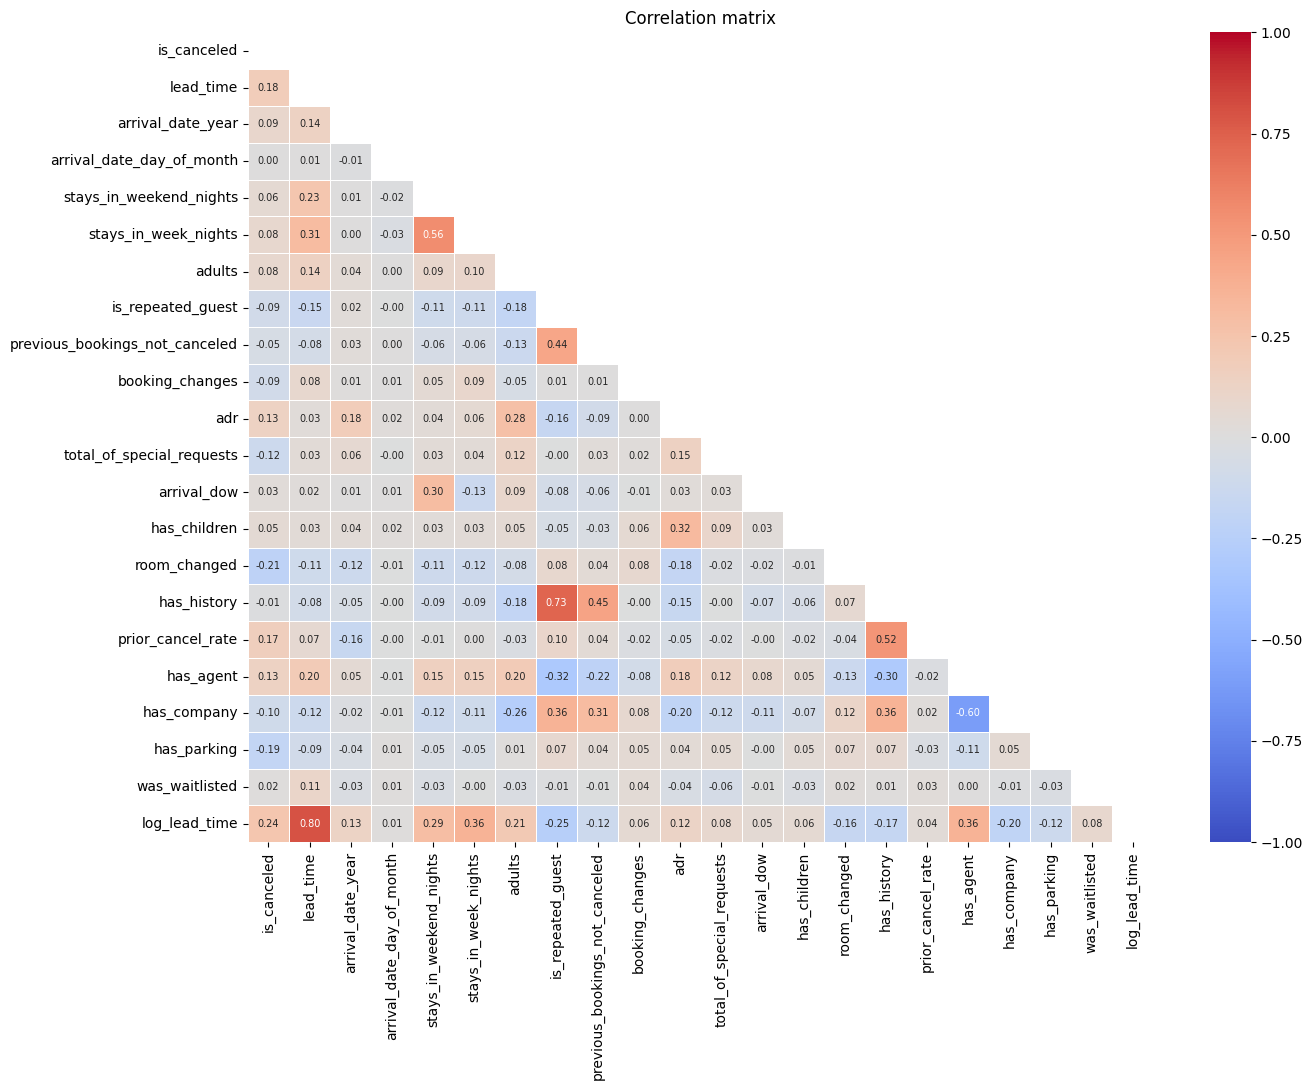

log_lead_time                     0.237897
room_changed                     -0.214962
has_parking                      -0.185757
lead_time                         0.183919
prior_cancel_rate                 0.169309
has_agent                         0.134147
adr                               0.134064
total_of_special_requests        -0.119570
has_company                      -0.096381
booking_changes                  -0.093484
is_repeated_guest                -0.089934
arrival_date_year                 0.087974
adults                            0.083885
stays_in_week_nights              0.082622
stays_in_weekend_nights           0.059381
previous_bookings_not_canceled   -0.051971
has_children                      0.051640
arrival_dow                       0.025985
was_waitlisted                    0.015432
has_history                      -0.008876
arrival_date_day_of_month         0.001706
Name: is_canceled, dtype: float64

In [8]:
corr = df1.select_dtypes(include="number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide the redundant upper triangle

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

# correlation of each variable with the target, strongest first
corr["is_canceled"].drop("is_canceled").sort_values(key=abs, ascending=False)

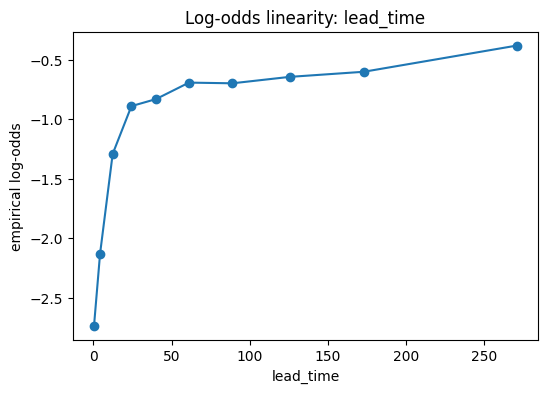

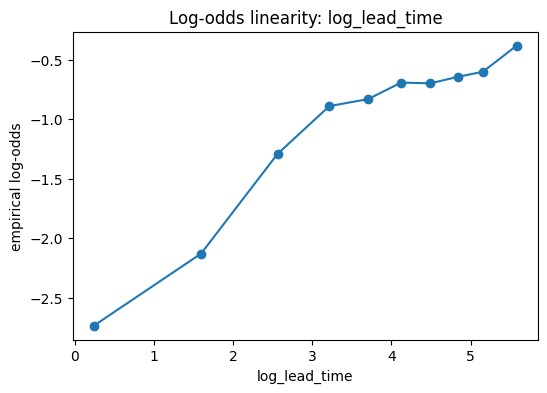

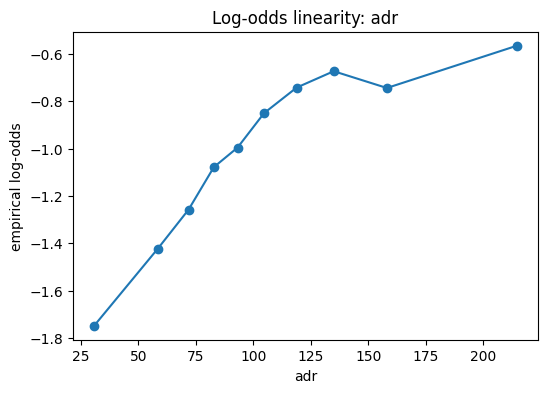

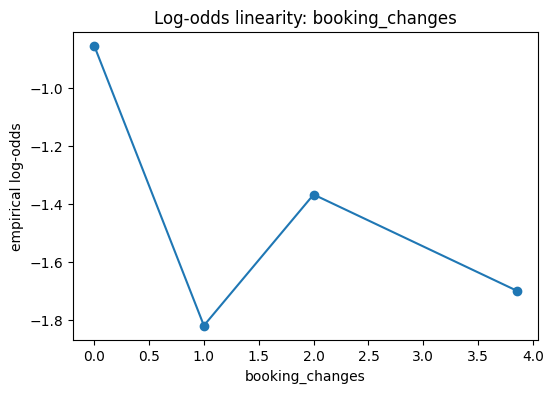

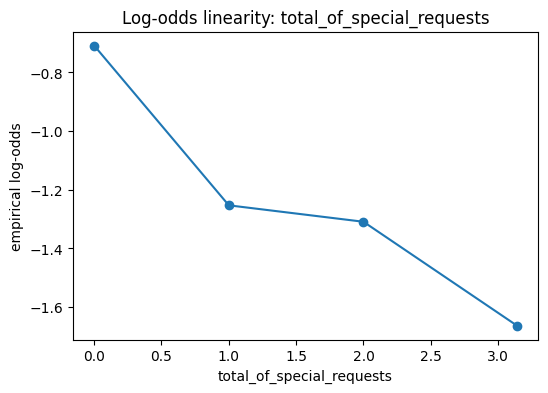

In [37]:
def logit_plot(df, col, target="is_canceled", bins=10, discrete=False, cap=None):
    x = df[col].clip(upper=cap) if cap is not None else df[col]
    groups = x if discrete else pd.qcut(x, bins, duplicates="drop")

    g = df.groupby(groups, observed=True).agg(
        x_mean=(col, "mean"),          # average x in each bin (not the interval midpoint)
        rate=(target, "mean"),
        n=(target, "size"),
    )
    g["rate"] = g["rate"].clip(0.001, 0.999)        # avoid log(0)
    g["log_odds"] = np.log(g["rate"] / (1 - g["rate"]))

    plt.figure(figsize=(6, 4))
    plt.plot(g["x_mean"], g["log_odds"], "o-")
    plt.xlabel(col); plt.ylabel("empirical log-odds")
    plt.title(f"Log-odds linearity: {col}")
    plt.show()

# continuous variables: quantile bins
for c in ["lead_time", "log_lead_time", "adr"]:
    logit_plot(df1, c)

# count variables: one point per value, rare high values lumped together
logit_plot(df1, "booking_changes", discrete=True, cap=3)
logit_plot(df1, "total_of_special_requests", discrete=True, cap=3)

In [38]:
# we observe having even one change to a booking goes w a much lower chance of cancelling, probably bcz guests who edit a booking are committed to the trip
df1["has_changes"] = (df1["booking_changes"] > 0).astype(int)

In [39]:
# Check adr == 0
total_nights = df1["stays_in_weekend_nights"] + df1["stays_in_week_nights"]
zero = df1["adr"] == 0

df1["adr_group"] = "adr>0"
df1.loc[zero & (total_nights == 0), "adr_group"] = "adr0_zero_nights"
df1.loc[zero & (total_nights > 0) & (df1["market_segment"] == "Complementary"), "adr_group"] = "adr0_complementary"
df1.loc[zero & (total_nights > 0) & (df1["market_segment"] != "Complementary"), "adr_group"] = "adr0_other"
df1.loc[zero & (total_nights > 0) & (df1["market_segment"] != "Complementary") & (df1["adults"] == 0), "adr_group"] = "adr0_other_adults0"

df1.groupby("adr_group")["is_canceled"].agg(["mean", "count"])

# 517 are zero-night (and 0 adr) - not errors
# 515 are complementary - not errors
# 402 have 0 adr, but are not free rooms and have >0 nights stayed
## of that 402, 61 record 0 adults (needs to be handled)
## of that 402, 341 record >0 adults:

df1.loc[zero & (total_nights > 0) & (df1["market_segment"] != "Complementary"), "market_segment"].value_counts()
# groups, offline TA/TO, and transient-party could price the room as part of a package or contract

df1 = df1.drop(columns = ["adr_group"])
# hence we drop the 61 records:
df1 = df1[~(zero & (total_nights > 0) & (df1["market_segment"] != "Complementary") & (df1["adults"] == 0))]

,mean,count
adr_group,,
adr0_complementary,0.122330,515
adr0_other,0.140762,341
adr0_zero_nights,0.050290,517
adr>0,0.276288,68273


market_segment
Groups           138
Offline TA/TO     94
Direct            60
Online TA         33
Corporate         16
Name: count, dtype: int64

In [40]:
# 1,434 bookings have adr = 0. These are explained by complimentary stays, zero-night bookings and package rates, and cancel at markedly lower rates, so we retain them and add an indicator variable rather than treating them as errors.
df1["adr_zero"] = (df1["adr"] == 0).astype(int)

In [41]:
pd.crosstab(df1["is_canceled"], df1["has_parking"])
# out of 19,013 cancellations, not a single one had a parking space. This perfect result could mean that the parking space is recorded when the guest arrives, so a cancelled booking can never have one.
# So we drop the parking variable
pd.crosstab(df1["is_canceled"], df1["room_changed"])
# 4.5% cancel rate when the room changed vs 31% when it didn't. The assigned room is typically decided at check-in, so a cancelled booking usually keeps its reserved room by default
# So we drop the room type variable

df1 = df1.drop(columns=["room_changed", "has_parking"])

KeyError: 'has_parking'

array([[<Axes: title={'center': 'log_lead_time'}>,
        <Axes: title={'center': 'lead_time'}>,
        <Axes: title={'center': 'adr'}>],
       [<Axes: title={'center': 'stays_in_weekend_nights'}>,
        <Axes: title={'center': 'stays_in_week_nights'}>,
        <Axes: title={'center': 'adults'}>],
       [<Axes: title={'center': 'booking_changes'}>,
        <Axes: title={'center': 'total_of_special_requests'}>,
        <Axes: title={'center': 'prior_cancel_rate'}>],
       [<Axes: title={'center': 'previous_bookings_not_canceled'}>,
        <Axes: >, <Axes: >]], dtype=object)

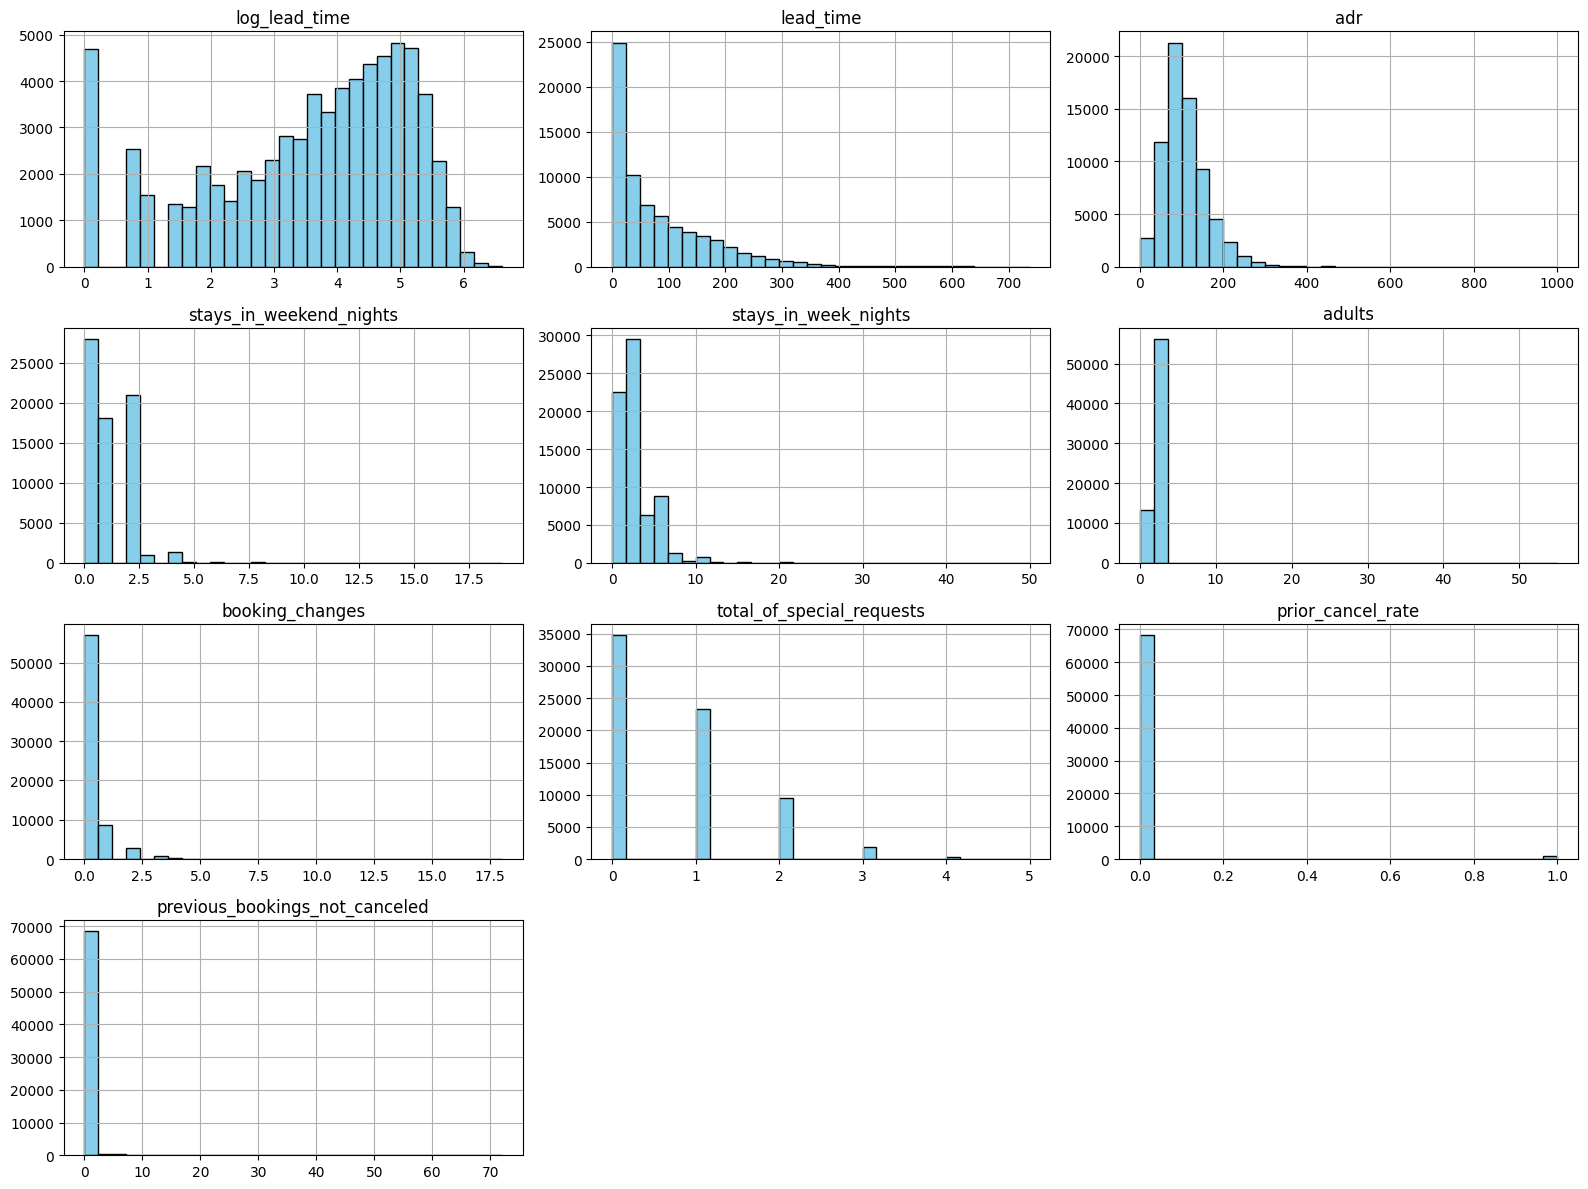

In [ ]:
num_cols = ["log_lead_time", "lead_time","adr", "stays_in_weekend_nights", "stays_in_week_nights",
            "adults", "booking_changes",
            "total_of_special_requests",
            "prior_cancel_rate",
            "previous_bookings_not_canceled"]

df1[num_cols].hist(bins=30, figsize=(16, 12), color="skyblue", edgecolor="black")
plt.tight_layout()
plt.show()

In [ ]:
# Multicollinearity checks - VIF
num_cols = ["log_lead_time", "adr", "stays_in_weekend_nights",
            "stays_in_week_nights", "adults", "booking_changes",
            "total_of_special_requests"]

Xv = add_constant(df1[num_cols].astype(float).dropna())
vif = pd.DataFrame({
    "feature": Xv.columns,
    "VIF": [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]
}).query("feature != 'const'").sort_values("VIF", ascending=False)
vif

,feature,VIF
4,stays_in_week_nights,1.545383
3,stays_in_weekend_nights,1.463410
1,log_lead_time,1.220840
5,adults,1.132316
2,adr,1.101342
7,total_of_special_requests,1.031661
6,booking_changes,1.010635


In [ ]:
# # to prepare for log regression
# cat_cols = ["hotel", "arrival_date_month", "meal", "market_segment",
#             "distribution_channel", "deposit_type",
#             "customer_type", "country_grp"]

# df1 = pd.get_dummies(df1, columns=cat_cols, drop_first=True)

MODELS

In [42]:
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score
from scipy import stats
from sklearn.model_selection import train_test_split

train, test = train_test_split(df1, test_size=0.2, random_state=888,
                               stratify=df1["is_canceled"])

def evaluate(formula, train, test):
    m = smf.logit(formula, data=train).fit(disp=0)
    return m, {
        "n_params": int(m.df_model),
        "AIC": round(m.aic, 1),
        "BIC": round(m.bic, 1),
        "pseudo_R2": round(m.prsquared, 3),
        "val_AUC": round(roc_auc_score(test["is_canceled"], m.predict(test)), 3),
    }

models = {
    "M1":   "is_canceled ~ log_lead_time",
    "M2":     "is_canceled ~ log_lead_time + adr + adr_zero",
    "M3":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)",
    "M4": "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)"
                      " + total_of_special_requests",
    "M5":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)"
                      " + total_of_special_requests"
                      " + C(market_segment) + C(hotel) + C(customer_type)",
    "M6":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)"
                    " + total_of_special_requests"
                    " + C(market_segment) + C(hotel) + C(customer_type)"
                    " + has_changes + prior_cancel_rate",
    "M7":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)"
                        " + total_of_special_requests"
                        " + C(market_segment) + C(hotel) + C(customer_type)"
                        " + has_changes + prior_cancel_rate +  C(country_grp)",
    "M8":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)" 
                            " + total_of_special_requests"
                            " + C(market_segment) + C(hotel) + C(customer_type)"
                            " + has_changes + prior_cancel_rate +  C(country_grp)"
                            " + C(arrival_dow) + C(meal)", # meal and arrival_dow gives nothing but adds 10 params
    "M9":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)" 
                                " + total_of_special_requests"
                                " + C(market_segment) + C(hotel) + C(customer_type)"
                                " + has_changes + prior_cancel_rate +  C(country_grp)"
                                " + stays_in_weekend_nights + stays_in_week_nights + adults +has_children", # stays in nights, adults, has_children, has_agent, was_waitlisted: not very useful but costs nthg
    "M10":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)" 
                                            " + total_of_special_requests"
                                            " + C(market_segment) + C(hotel) + C(customer_type)"
                                            " + has_changes + prior_cancel_rate +  C(country_grp)"
                                            " + has_history",
    "M11":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)" 
                                    " + C(np.minimum(total_of_special_requests,3))"
                                    " + C(market_segment) + C(hotel) + C(customer_type)"
                                    " + has_changes + prior_cancel_rate +  C(country_grp)"
                                    " + has_history+ C(arrival_date_month)+C(market_segment):log_lead_time",
    "M12":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)" 
                                        " + C(np.minimum(total_of_special_requests,3))"
                                        " + C(market_segment) + C(hotel) + C(customer_type)"
                                        " + has_changes + prior_cancel_rate +  C(country_grp)"
                                        " + has_history+ C(arrival_date_month)+C(market_segment):log_lead_time"
                                        " + C(arrival_date_year)",
    "M13":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)" 
                                            " + C(np.minimum(total_of_special_requests,3))"
                                            " + C(market_segment) + C(hotel) + C(customer_type)"
                                            " + has_changes + prior_cancel_rate +  C(country_grp)"
                                            " + has_history+ C(arrival_date_month)+C(market_segment):log_lead_time"
                                            " + C(arrival_date_year) + C(top_agent)",
    "all":   "is_canceled ~ log_lead_time + adr + adr_zero + C(deposit_type)"
    " + has_changes + total_of_special_requests"
    " + prior_cancel_rate + has_history + previous_bookings_not_canceled + is_repeated_guest"
    " + C(market_segment) + C(hotel) + C(customer_type) + C(meal) + C(country_grp)"
    " + C(arrival_date_month) + C(arrival_dow)"
    " + stays_in_weekend_nights + stays_in_week_nights + adults + has_children"
    " + has_agent + has_company + was_waitlisted"
}

fitted, rows = {}, {}
for name, f in models.items():
    try:
        fitted[name], rows[name] = evaluate(f, train, test)
    except Exception as e:
        print(f"{name} FAILED: {type(e).__name__}")

pd.DataFrame(rows).T

,n_params,AIC,BIC,pseudo_R2,val_AUC
M1,1.0,61864.4,61882.2,0.053,0.649
M2,3.0,61142.6,61178.3,0.064,0.668
M3,5.0,60023.6,60077.1,0.081,0.677
M4,6.0,58735.3,58797.8,0.101,0.701
M5,16.0,54401.9,54553.7,0.167,0.763
M6,18.0,52280.0,52449.7,0.200,0.782
M7,28.0,49173.4,49432.3,0.248,0.816
M8,37.0,49096.3,49435.6,0.249,0.816
M9,32.0,49002.2,49296.8,0.251,0.817
M10,29.0,48865.6,49133.5,0.253,0.819


<BarContainer object of 4 artists>

Text(0, 33.488624612202685, '33%\n(n=34,812)')

Text(1, 22.71745289093016, '22%\n(n=23,297)')

Text(2, 21.76461211477152, '21%\n(n=9,410)')

Text(3, 16.437940761636106, '16%\n(n=2,127)')

(0.0, 40.0)

... (3 outputs left out)

[Text(0, 0, '0'), Text(1, 0, '1'), Text(2, 0, '2'), Text(3, 0, '3+')]

Text(0.5, 0, 'Number of special requests')

Text(0, 0.5, 'Log-odds of cancelling')

Text(0.5, 1.0, 'Actual log-odds vs straight-line fit')

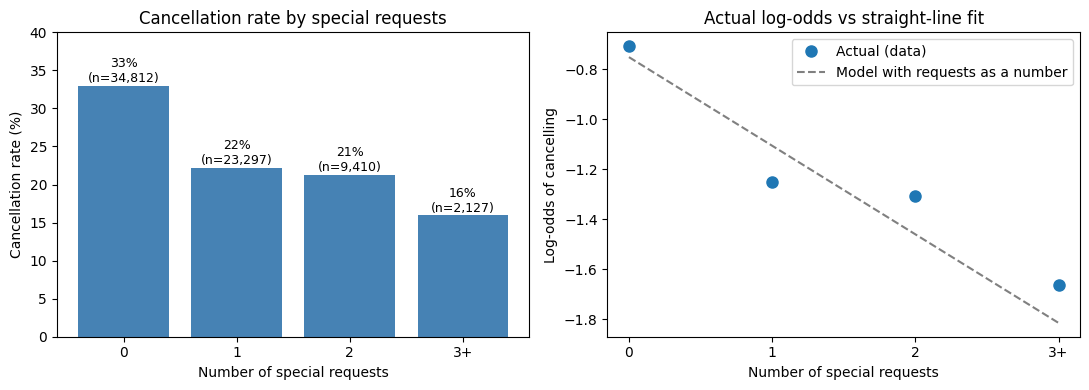

80577.75983289666 80439.01061314886


In [43]:
# to prove C(total_of_special_req):
# cancel rate and log-odds per level (3+ grouped)
s = df1["total_of_special_requests"].clip(upper=3)
g = df1.groupby(s)["is_canceled"].agg(rate="mean", n="size")
g["log_odds"] = np.log(g["rate"] / (1 - g["rate"]))

# what the "as a number" model forces: a straight line
m_num = smf.logit("is_canceled ~ total_of_special_requests", data=df1).fit(disp=0)
x = g.index.to_numpy()
line = m_num.params["Intercept"] + m_num.params["total_of_special_requests"] * x

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# left: cancellation rate
ax[0].bar(["0", "1", "2", "3+"], g["rate"] * 100, color="steelblue")
for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
    ax[0].text(i, r * 100 + 0.5, f"{r:.0%}\n(n={n:,})", ha="center", fontsize=9)
ax[0].set_ylim(0, 40)
ax[0].set_xlabel("Number of special requests"); ax[0].set_ylabel("Cancellation rate (%)")
ax[0].set_title("Cancellation rate by special requests")

# right: actual log-odds vs straight-line fit
ax[1].plot(x, g["log_odds"], "o", markersize=8, label="Actual (data)")
ax[1].plot(x, line, "--", color="grey", label="Model with requests as a number")
ax[1].set_xticks(x); ax[1].set_xticklabels(["0", "1", "2", "3+"])
ax[1].set_xlabel("Number of special requests"); ax[1].set_ylabel("Log-odds of cancelling")
ax[1].set_title("Actual log-odds vs straight-line fit")
ax[1].legend()

plt.tight_layout()
plt.show()

# compare aic if numeric vs categorical
m_cat = smf.logit("is_canceled ~ C(np.minimum(total_of_special_requests, 3))", data=df1).fit(disp=0)
print(m_num.aic, m_cat.aic) # lower if category

The log-odds plot showed unequal steps, with the largest drop between 0 and 1 request, so we treated it as categorical. Levels above 3 were merged due to small counts (n = 274)

Text(0.5, 0, 'Lead time (days between booking and arrival)')

Text(0, 0.5, 'Cancellation rate (%)')

Text(0.5, 1.0, 'Lead time raises cancellation risk more for some segments than others')

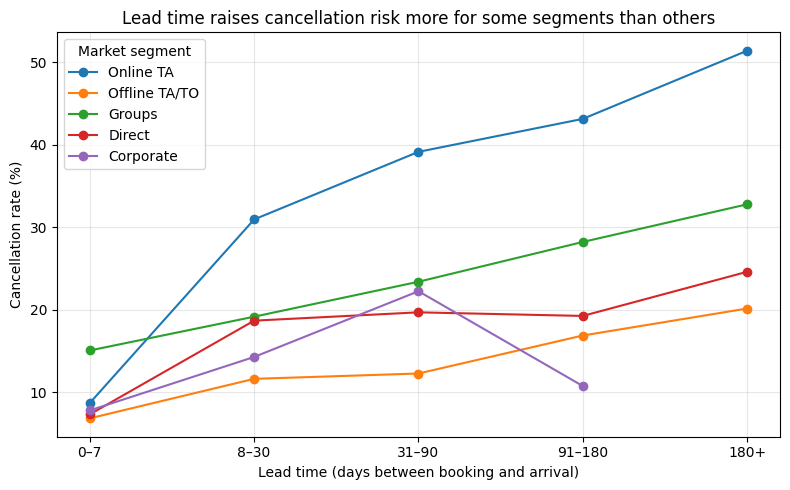

In [44]:
# to prove market_segment*log_lead_time:
segments = ["Online TA", "Offline TA/TO", "Groups", "Direct", "Corporate"]
bins   = [-1, 7, 30, 90, 180, df1["lead_time"].max()]
labels = ["0–7", "8–30", "31–90", "91–180", "180+"]

d = df1[df1["market_segment"].isin(segments)].copy()
d["lead_bin"] = pd.cut(d["lead_time"], bins=bins, labels=labels)

tab = (d.groupby(["market_segment", "lead_bin"], observed=True)["is_canceled"]
         .agg(rate="mean", n="size")
         .reset_index())
tab = tab[tab["n"] >= 50]          # hide points based on very few bookings

fig, ax = plt.subplots(figsize=(8, 5))
for seg in segments:
    t = tab[tab["market_segment"] == seg]
    ax.plot(t["lead_bin"].astype(str), t["rate"] * 100, marker="o", label=seg)

ax.set_xlabel("Lead time (days between booking and arrival)")
ax.set_ylabel("Cancellation rate (%)")
ax.set_title("Lead time raises cancellation risk more for some segments than others")
ax.legend(title="Market segment")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Cancellation rate by lead time and market segment. The lines are not parallel; 
# long lead times raise risk far more for Online TA bookings, motivating a segment × lead-time interaction.

EDA showed the lead-time effect differs by segment (e.g. 9%→51% for Online TA vs 7%→20% for Offline TA/TO), so we added a segment × lead-time interaction.

In [45]:
# Likelihood Ratio test
def lr_test(small, big):
    stat = 2 * (big.llf - small.llf)
    df_diff = big.df_model - small.df_model
    return round(stat, 1), int(df_diff), stats.chi2.sf(stat, df_diff)   # (statistic, df, p-value)

lr_test(fitted["M11"], fitted["all"])
# (-268.6, 11, 1.0) means big fits significantly worse

(-248.9, 10, 1.0)

## Final model: gradient boosting (Section 6.4, Appendix E) and model comparison (Section 7)

These cells are self-contained. They rebuild the modelling data from `HotelBookings.csv` exactly as described in Sections 2–4 of the report (69,380 bookings, 22 inputs, with country, parking and room change excluded as leakage), so the results do not depend on the exploration cells above. Every model uses the same stratified 80/20 split (seed 888), five-fold cross-validation on the training set, a cut-off chosen to maximise out-of-fold F1, and one evaluation on the validation set (Section 5).

In [46]:
# Modelling data (report Sections 2-4)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score,
                             recall_score, f1_score, accuracy_score, confusion_matrix, roc_curve,
                             precision_recall_curve)
from xgboost import XGBClassifier

SEED = 888
np.random.seed(SEED)

# Section 2: cleaning
hb = pd.read_csv("HotelBookings.csv")
n_raw = len(hb)
hb = hb[~((hb["adults"] > 4) | (hb["adr"] > 1000) | (hb["adults"] == 0))].copy()
hb["children"] = hb["children"].fillna(0)
hb["meal"] = hb["meal"].replace("Undefined", "SC")
hb["market_segment"] = hb["market_segment"].replace("Undefined", "Online TA")
hb["reserved_room_type"] = hb["reserved_room_type"].replace({"L": "A", "P": "A"})
print(f"Bookings: {n_raw:,} -> {len(hb):,} ({n_raw - len(hb)} removed)")

# Section 4: features
prior = hb["previous_cancellations"] + hb["previous_bookings_not_canceled"]
hb["log_lead_time"] = np.log1p(hb["lead_time"])
hb["adr_zero"] = (hb["adr"] == 0).astype(int)
hb["has_children"] = ((hb["children"] + hb["babies"]) > 0).astype(int)
hb["has_history"] = (prior > 0).astype(int)
hb["prior_cancel_rate"] = (hb["previous_cancellations"] / prior.replace(0, np.nan)).fillna(0)
hb["has_changes"] = (hb["booking_changes"] > 0).astype(int)
hb["was_waitlisted"] = (hb["days_in_waiting_list"] > 0).astype(int)
hb["has_company"] = hb["company"].notna().astype(int)
hb["special_requests"] = hb["total_of_special_requests"].clip(upper=3).astype(str)   # "3" means 3 or more
# variables tested as leakage in Section 5 (used only in the leakage check)
hb["has_parking"] = (hb["required_car_parking_spaces"] > 0).astype(int)
hb["room_changed"] = (hb["reserved_room_type"] != hb["assigned_room_type"]).astype(int)

# split first, then pool agents and countries using the training rows only
y_hb = hb["is_canceled"]
tr_idx, va_idx = train_test_split(hb.index, test_size=0.2, stratify=y_hb, random_state=SEED)
ytr, yva = y_hb[tr_idx].to_numpy(), y_hb[va_idx].to_numpy()

top_agents = hb.loc[tr_idx, "agent"].value_counts(normalize=True, dropna=False).loc[lambda s: s >= 0.01].index
hb["top_agent"] = np.where(hb["agent"].isna(), "None",
                  np.where(hb["agent"].isin(top_agents), hb["agent"].fillna(0).astype(int).astype(str), "Other"))
top_countries = hb.loc[tr_idx, "country"].value_counts().nlargest(10).index
hb["country_grp"] = hb["country"].where(hb["country"].isin(top_countries), "OTHER")
for s in hb.loc[tr_idx, "market_segment"].unique():          # segment x lead time (logistic regression only)
    hb[f"lead_x_{s}"] = hb["log_lead_time"] * (hb["market_segment"] == s)

CAT = ["hotel", "arrival_date_month", "meal", "market_segment", "reserved_room_type",
       "deposit_type", "customer_type", "top_agent", "special_requests"]
NUM = ["log_lead_time", "adr", "adr_zero", "stays_in_weekend_nights", "stays_in_week_nights", "adults",
       "has_children", "is_repeated_guest", "has_history", "prior_cancel_rate", "has_changes",
       "was_waitlisted", "has_company"]
INTER = [c for c in hb.columns if c.startswith("lead_x_")]
print(f"Inputs: {len(CAT)} categorical + {len(NUM)} numeric")
print(f"Train {len(tr_idx):,} | validation {len(va_idx):,} | cancellation rate {ytr.mean():.3f} / {yva.mean():.3f}")

def prep(cat, num, scale):
    """One-hot encode categoricals (unseen levels ignored); scale numerics only for linear and distance models."""
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                              ("num", StandardScaler() if scale else "passthrough", num)])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Bookings: 69,710 -> 69,380 (330 removed)
Inputs: 9 categorical + 13 numeric
Train 55,504 | validation 13,876 | cancellation rate 0.273 / 0.273


### Tuning gradient boosting (Table GB2)
Grid search over learning rate, tree depth and number of trees, with three-fold cross-validation on the training set, scored on ROC-AUC. Each tree uses a random 80% of rows and columns.

In [47]:
gb_search = GridSearchCV(
    Pipeline([("prep", prep(CAT, NUM, False)),
              ("model", XGBClassifier(subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                                      eval_metric="logloss", random_state=SEED, n_jobs=2))]),
    {"model__learning_rate": [0.05, 0.1], "model__max_depth": [4, 6], "model__n_estimators": [300, 600]},
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), scoring="roc_auc")
_ = gb_search.fit(hb.loc[tr_idx, CAT + NUM], ytr)

GB_BEST = {k.replace("model__", ""): v for k, v in gb_search.best_params_.items()}
print("Best settings:", GB_BEST)

table_gb2 = pd.DataFrame(gb_search.cv_results_)[["param_model__learning_rate", "param_model__max_depth",
                                                 "param_model__n_estimators", "mean_test_score"]]
table_gb2.columns = ["Learning rate", "Max depth", "Number of trees", "CV ROC-AUC"]
table_gb2.sort_values("CV ROC-AUC", ascending=False).round(4)

Best settings: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 600}


,Learning rate,Max depth,Number of trees,CV ROC-AUC
3,0.05,6,600,0.8340
6,0.10,6,300,0.8326
2,0.05,6,300,0.8323
5,0.10,4,600,0.8319
1,0.05,4,600,0.8309
7,0.10,6,600,0.8307
4,0.10,4,300,0.8306
0,0.05,4,300,0.8269


### Common evaluation protocol (Section 5)
`evaluate()` runs five-fold cross-validation on the training set, picks the cut-off that maximises F1 on the out-of-fold predictions, then scores the validation set once.

In [48]:
results, store = {}, {}

def evaluate(name, model, cat=CAT, num=NUM, scale=False, calibrate=False):
    Xtr, Xva = hb.loc[tr_idx, cat + num], hb.loc[va_idx, cat + num]
    pipe = Pipeline([("prep", prep(cat, num, scale)), ("model", model)])
    oof = cross_val_predict(pipe, Xtr, ytr, cv=cv5, method="predict_proba")[:, 1]
    folds = [v for _, v in cv5.split(Xtr, ytr)]
    fold_auc = [roc_auc_score(ytr[v], oof[v]) for v in folds]
    pipe.fit(Xtr, ytr)
    p = pipe.predict_proba(Xva)[:, 1]
    if calibrate:   # isotonic calibration fitted on out-of-fold training predictions (kNN)
        iso = IsotonicRegression(out_of_bounds="clip").fit(oof, ytr)
        oof, p = iso.predict(oof), iso.predict(p)
    cuts = np.round(np.arange(0.05, 0.951, 0.01), 2)
    cut = cuts[np.argmax([f1_score(ytr, oof >= t) for t in cuts])]
    pred = p >= cut
    results[name] = {"CV ROC-AUC": np.mean(fold_auc), "CV SD": np.std(fold_auc),
                     "Val ROC-AUC": roc_auc_score(yva, p), "PR-AUC": average_precision_score(yva, p),
                     "Brier": brier_score_loss(yva, p), "Cut-off": cut,
                     "Precision": precision_score(yva, pred), "Recall": recall_score(yva, pred),
                     "F1": f1_score(yva, pred), "Accuracy": accuracy_score(yva, pred)}
    store[name] = {"pipe": pipe, "oof": oof, "p": p, "cut": cut, "folds": folds, "fold_auc": fold_auc}
    print(f"{name}: validation ROC-AUC {results[name]['Val ROC-AUC']:.3f}, F1 {results[name]['F1']:.3f} at cut-off {cut:.2f}")

def tuned_gb():
    return XGBClassifier(**GB_BEST, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                         eval_metric="logloss", random_state=SEED, n_jobs=2)

### Final model: tuned gradient boosting (Section 6.4, Table GB1)

In [49]:
evaluate("Gradient boosting (tuned)", tuned_gb())
gb, gb_r = store["Gradient boosting (tuned)"], results["Gradient boosting (tuned)"]

cv_scores = {m: [f(ytr[v], gb["oof"][v]) for v in gb["folds"]]
             for m, f in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score), ("Brier score", brier_score_loss)]}
table_gb1 = pd.DataFrame(
    {"Cross-validation mean": [np.mean(s) for s in cv_scores.values()] + [np.nan] * 4,
     "Standard deviation": [np.std(s) for s in cv_scores.values()] + [np.nan] * 4,
     "Validation": [gb_r[k] for k in ["Val ROC-AUC", "PR-AUC", "Brier", "Precision", "Recall", "F1", "Accuracy"]]},
    index=["ROC-AUC", "PR-AUC", "Brier score", "Precision", "Recall", "F1", "Accuracy"])
print(f"Table GB1 (precision, recall, F1 and accuracy at the {gb['cut']:.2f} cut-off)")
table_gb1.round(4)

Gradient boosting (tuned): validation ROC-AUC 0.842, F1 0.637 at cut-off 0.31
Table GB1 (precision, recall, F1 and accuracy at the 0.31 cut-off)


,Cross-validation mean,Standard deviation,Validation
ROC-AUC,0.8359,0.0043,0.8423
PR-AUC,0.7005,0.0074,0.7082
Brier score,0.1346,0.0018,0.1329
Precision,NaN,NaN,0.5898
Recall,NaN,NaN,0.6925
F1,NaN,NaN,0.6370
Accuracy,NaN,NaN,0.7847


### Figures GB1 to GB3
Feature importance is permutation importance on the validation set: the drop in ROC-AUC when one input is shuffled.

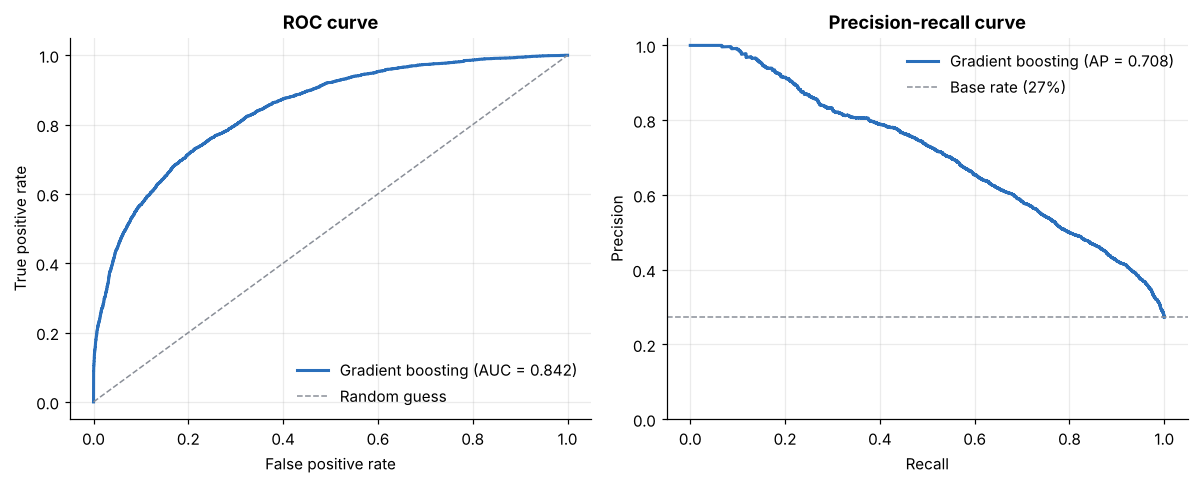

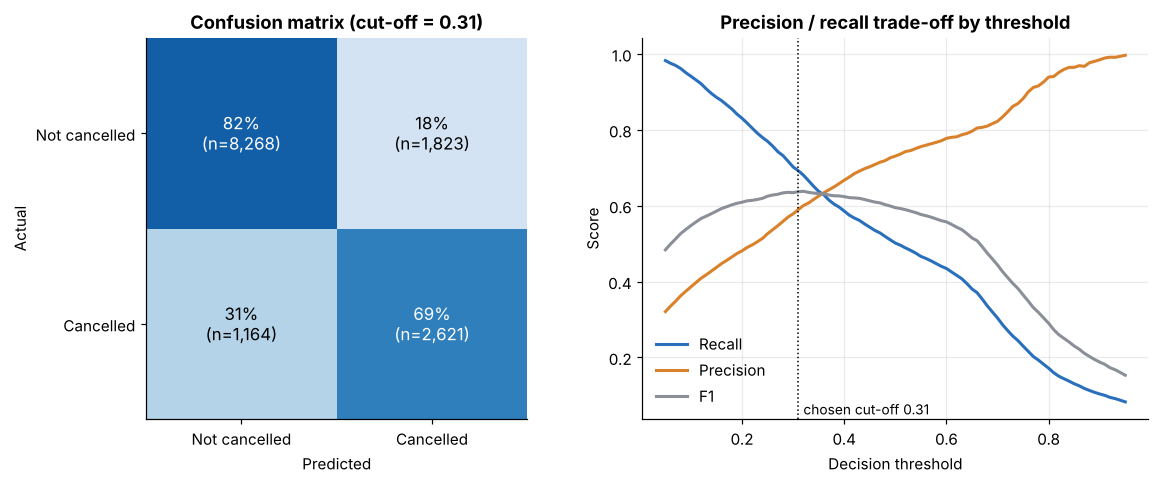

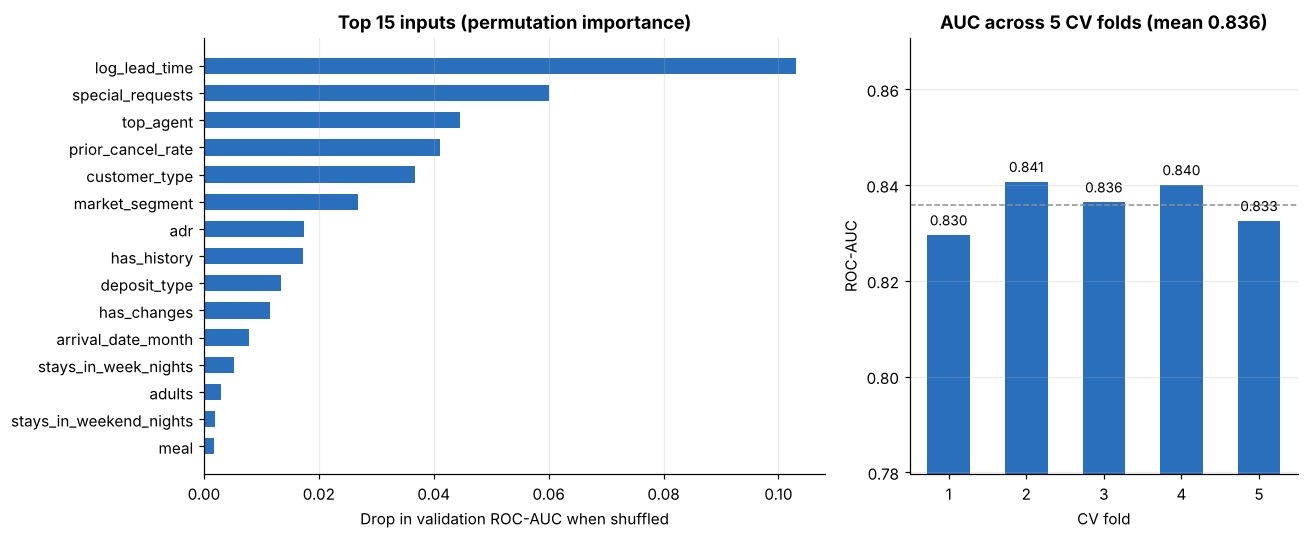

In [50]:
Xva_gb = hb.loc[va_idx, CAT + NUM]
perm = permutation_importance(gb["pipe"], Xva_gb, yva, scoring="roc_auc", n_repeats=5, random_state=SEED)
gb_importance = pd.Series(perm.importances_mean, index=Xva_gb.columns).sort_values(ascending=False)

BLUE, ORANGE, GREY = "#2a6fbb", "#d9822b", "#8a8f98"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "figure.dpi": 110})

def figure_gb1():   # ROC and precision-recall curves
    p = gb["p"]
    fpr, tpr, _ = roc_curve(yva, p)
    prec, rec, _ = precision_recall_curve(yva, p)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].plot(fpr, tpr, color=BLUE, lw=2, label=f"Gradient boosting (AUC = {gb_r['Val ROC-AUC']:.3f})")
    ax[0].plot([0, 1], [0, 1], "--", color=GREY, lw=1, label="Random guess")
    ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    ax[0].legend(loc="lower right", frameon=False)
    ax[1].plot(rec, prec, color=BLUE, lw=2, label=f"Gradient boosting (AP = {gb_r['PR-AUC']:.3f})")
    ax[1].axhline(yva.mean(), ls="--", color=GREY, lw=1, label=f"Base rate ({yva.mean():.0%})")
    ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve", ylim=(0, 1.02))
    ax[1].legend(loc="upper right", frameon=False)
    plt.tight_layout(); plt.show()

def figure_gb2():   # confusion matrix at the chosen cut-off, and threshold trade-off
    p, cut = gb["p"], gb["cut"]
    cm = confusion_matrix(yva, p >= cut)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
    ax[0].grid(False)
    for i in range(2):
        for j in range(2):
            ax[0].text(j, i, f"{cm_pct[i, j]:.0%}\n(n={cm[i, j]:,})", ha="center", va="center",
                       color="white" if cm_pct[i, j] > 0.5 else "black", fontsize=11)
    ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Not cancelled", "Cancelled"])
    ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Not cancelled", "Cancelled"])
    ax[0].set(xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix (cut-off = {cut:.2f})")
    ts = np.linspace(0.05, 0.95, 91)
    ax[1].plot(ts, [recall_score(yva, p >= t) for t in ts], color=BLUE, lw=2, label="Recall")
    ax[1].plot(ts, [precision_score(yva, p >= t, zero_division=0) for t in ts], color=ORANGE, lw=2, label="Precision")
    ax[1].plot(ts, [f1_score(yva, p >= t) for t in ts], color=GREY, lw=2, label="F1")
    ax[1].axvline(cut, ls=":", color="black", lw=1)
    ax[1].text(cut + 0.01, 0.05, f"chosen cut-off {cut:.2f}", fontsize=9)
    ax[1].set(xlabel="Decision threshold", ylabel="Score", title="Precision / recall trade-off by threshold")
    ax[1].legend(frameon=False)
    plt.tight_layout(); plt.show()

def figure_gb3():   # top 15 inputs and AUC across the five CV folds
    top = gb_importance.head(15)[::-1]
    fa = np.array(gb["fold_auc"])
    fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.6, 1]})
    ax[0].barh(top.index, top.values, color=BLUE, height=0.6)
    ax[0].set(xlabel="Drop in validation ROC-AUC when shuffled", title="Top 15 inputs (permutation importance)")
    ax[0].grid(axis="y", visible=False)
    ax[1].bar(range(1, 6), fa, color=BLUE, width=0.55)
    ax[1].axhline(fa.mean(), ls="--", color=GREY, lw=1)
    for i, v in enumerate(fa, 1):
        ax[1].text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
    ax[1].set(ylim=(fa.min() - 0.05, fa.max() + 0.03), xlabel="CV fold", ylabel="ROC-AUC",
              title=f"AUC across 5 CV folds (mean {fa.mean():.3f})")
    ax[1].grid(axis="x", visible=False)
    plt.tight_layout(); plt.show()

figure_gb1()
figure_gb2()
figure_gb3()

### Model comparison under the common protocol (Section 7, Table A9)
Each candidate uses its settings from Section 6 (random forest without its feature-selection step; kNN probabilities calibrated with isotonic regression). The last two rows are checks, not candidates: gradient boosting at default settings, and the tuned model with the leaky variables added back.

In [51]:
evaluate("Random forest", RandomForestClassifier(n_estimators=300, max_depth=25, min_samples_leaf=5,
                                                 max_features="sqrt", n_jobs=2, random_state=SEED))
evaluate("Decision tree", DecisionTreeClassifier(criterion="entropy", max_depth=15, min_samples_leaf=100,
                                                class_weight="balanced", random_state=SEED))
evaluate("Logistic regression", LogisticRegression(max_iter=2000), num=NUM + INTER, scale=True)
evaluate("kNN", KNeighborsClassifier(n_neighbors=35, weights="distance", p=1, n_jobs=2), scale=True, calibrate=True)
evaluate("Check: GB, default settings", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=2))
evaluate("Check: tuned GB + country, parking, room change", tuned_gb(),
         cat=CAT + ["country_grp"], num=NUM + ["has_parking", "room_changed"])

table_a9 = pd.DataFrame(results).T[["CV ROC-AUC", "Val ROC-AUC", "PR-AUC", "Brier", "Cut-off",
                                    "Precision", "Recall", "F1"]].astype(float)
table_a9.round(3)

Random forest: validation ROC-AUC 0.839, F1 0.636 at cut-off 0.33


Decision tree: validation ROC-AUC 0.816, F1 0.602 at cut-off 0.51


Logistic regression: validation ROC-AUC 0.814, F1 0.603 at cut-off 0.33


kNN: validation ROC-AUC 0.812, F1 0.615 at cut-off 0.31


Check: GB, default settings: validation ROC-AUC 0.838, F1 0.633 at cut-off 0.32


Check: tuned GB + country, parking, room change: validation ROC-AUC 0.917, F1 0.733 at cut-off 0.35


,CV ROC-AUC,Val ROC-AUC,PR-AUC,Brier,Cut-off,Precision,Recall,F1
Gradient boosting (tuned),0.836,0.842,0.708,0.133,0.31,0.590,0.692,0.637
Random forest,0.833,0.839,0.698,0.136,0.33,0.618,0.655,0.636
Decision tree,0.806,0.816,0.658,0.172,0.51,0.511,0.734,0.602
Logistic regression,0.810,0.814,0.673,0.142,0.33,0.560,0.654,0.603
kNN,0.804,0.812,0.634,0.144,0.31,0.582,0.652,0.615
"Check: GB, default settings",0.832,0.838,0.701,0.134,0.32,0.591,0.682,0.633
"Check: tuned GB + country, parking, room change",0.911,0.917,0.806,0.102,0.35,0.669,0.811,0.733


In [52]:
# Is gradient boosting's lead real? Bootstrap the validation set (1,000 resamples).
rng = np.random.default_rng(SEED)
gb_p = gb["p"]
rivals = ["Random forest", "Decision tree", "Logistic regression", "kNN"]
boot_gb, boot_gap = [], {r: [] for r in rivals}
for _ in range(1000):
    i = rng.integers(0, len(yva), len(yva))
    a = roc_auc_score(yva[i], gb_p[i])
    boot_gb.append(a)
    for r in rivals:
        boot_gap[r].append(a - roc_auc_score(yva[i], store[r]["p"][i]))

print(f"Gradient boosting validation ROC-AUC: {gb_r['Val ROC-AUC']:.3f} "
      f"(95% interval {np.percentile(boot_gb, 2.5):.3f} to {np.percentile(boot_gb, 97.5):.3f})")
pd.DataFrame({r: {"ROC-AUC lead of gradient boosting": np.mean(d), "95% low": np.percentile(d, 2.5),
                  "95% high": np.percentile(d, 97.5)} for r, d in boot_gap.items()}).T.round(4)

Gradient boosting validation ROC-AUC: 0.842 (95% interval 0.835 to 0.850)


,ROC-AUC lead of gradient boosting,95% low,95% high
Random forest,0.0031,0.0007,0.0055
Decision tree,0.0261,0.0220,0.0305
Logistic regression,0.0279,0.0236,0.0322
kNN,0.0299,0.0248,0.0352


### Figure 10: ROC and precision-recall curves of the five candidates

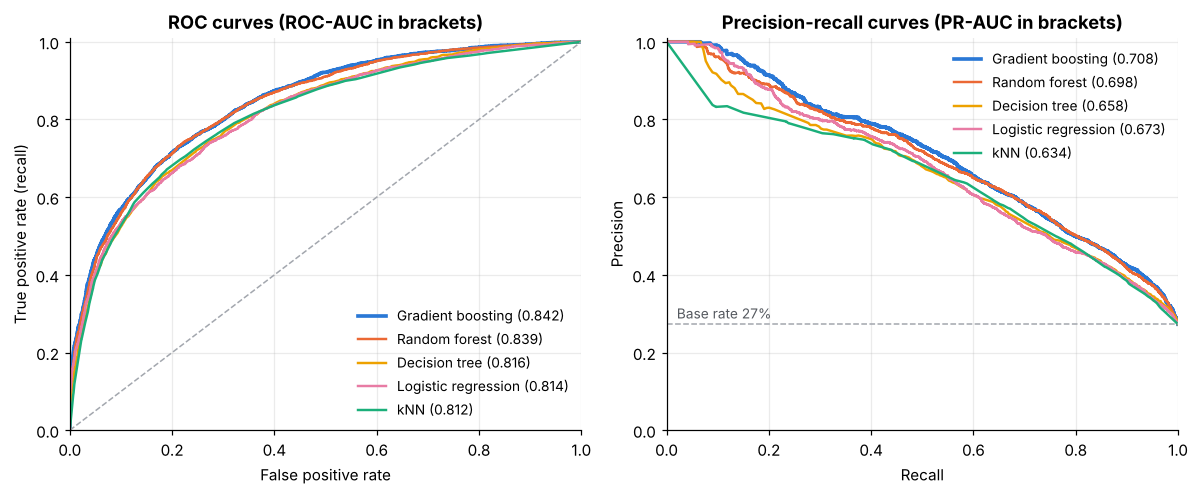

In [53]:
def figure_10():
    lines = [("Gradient boosting (tuned)", "Gradient boosting", "#2a78d6", 2.4),
             ("Random forest", "Random forest", "#eb6834", 1.6),
             ("Decision tree", "Decision tree", "#eda100", 1.6),
             ("Logistic regression", "Logistic regression", "#e87ba4", 1.6),
             ("kNN", "kNN", "#1baf7a", 1.6)]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
    for key, label, color, lw in lines:
        p = store[key]["p"]
        fpr, tpr, _ = roc_curve(yva, p)
        prec, rec, _ = precision_recall_curve(yva, p)
        ax[0].plot(fpr, tpr, color=color, lw=lw, label=f"{label} ({results[key]['Val ROC-AUC']:.3f})")
        ax[1].plot(rec, prec, color=color, lw=lw, label=f"{label} ({results[key]['PR-AUC']:.3f})")
    ax[0].plot([0, 1], [0, 1], ls="--", color="#a3a7ae", lw=1)
    ax[1].axhline(yva.mean(), ls="--", color="#a3a7ae", lw=1)
    ax[1].text(0.02, yva.mean() + 0.015, f"Base rate {yva.mean():.0%}", color="#55595f", fontsize=9)
    ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", xlim=(0, 1), ylim=(0, 1.01),
              title="ROC curves (ROC-AUC in brackets)")
    ax[1].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.01),
              title="Precision-recall curves (PR-AUC in brackets)")
    ax[0].legend(frameon=False, fontsize=9, loc="lower right")
    ax[1].legend(frameon=False, fontsize=9, loc="upper right")
    plt.tight_layout(); plt.show()

figure_10()

ignore below

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# one-hot encode the string columns here so df1 keeps its categoricals for the formula models
X = pd.get_dummies(df1.drop(columns=["is_canceled", "lead_time"]), drop_first=True).astype(float)
y = df1['is_canceled'].values

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=888, stratify=y)

scaler = StandardScaler()
X_tr_s  = scaler.fit_transform(X_tr)
X_val_s = scaler.transform(X_val)

model = LogisticRegression(penalty=None, max_iter=1000)
model.fit(X_tr_s, y_tr)

THRESHOLD = 0.35
probs = model.predict_proba(X_val_s)[:, 1]
y_pred2 = (probs >= THRESHOLD).astype(int)

print(f"Accuracy:  {accuracy_score(y_val, y_pred2)}")
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred2))
print(f"Precision: {precision_score(y_val, y_pred2)}")
print(f"Recall:    {recall_score(y_val, y_pred2)}")
print(f"ROC-AUC:   {roc_auc_score(y_val, probs):.4f}")
print(f"F1 Score:  {f1_score(y_val, y_pred2)}")

In [ ]:
print("train:", roc_auc_score(y_tr, model.predict_proba(X_tr_s)[:, 1]))
print("valid:", roc_auc_score(y_val, model.predict_proba(X_val_s)[:, 1]))

In [ ]:
pd.set_option("display.max_rows", None)

coefs = pd.DataFrame({
    "feature": X.columns,
    "coef": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0])
}).sort_values("odds_ratio", ascending=False)

print("intercept:", model.intercept_[0])
coefs
#pd.reset_option("display.max_rows")

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            random_state=888, n_jobs=-1)
rf.fit(X_tr, y_tr)        # unscaled is fine for trees
print("RF valid AUC:", roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]))

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(random_state=888, max_iter=300,
                                     learning_rate=0.1, early_stopping=True)
hgb.fit(X_tr, y_tr)
print("HGB valid AUC:", roc_auc_score(y_val, hgb.predict_proba(X_val)[:, 1]))